# Microbial genome variant calling and bioinformatics file formats
**GenBank, FASTA, FASTQ, SAM/BAM, VCF and Newick in one reproducible pipeline**

Author: Ahmed Hamdy

## 1. Goal and scope
Take a real bacterial replicon, call variants in several strains, and follow the data through every standard file format:

| Step | Format | Tool |
|---|---|---|
| Reference with gene annotation | GenBank, FASTA | Biopython |
| Sequencing reads | FASTQ | Python (simulated) |
| Read alignment | SAM / BAM | bwa mem, samtools |
| Variant calls | VCF | bcftools |
| Strain relationships | Newick | Biopython (neighbour joining) |

**Reference:** NCBI RefSeq NC_005816, *Yersinia pestis* plasmid pPCP1 (9,609 bp, 10 annotated genes).

**Important:** the four strains and their reads are **simulated** from the real reference with known mutations. This is deliberate: because the true variants are known, the pipeline can be validated (precision, recall, and whether the tree recovers the true relationships). Real sequencing data would add indels, repeats and mixed populations.

In [1]:
import importlib.util, subprocess, sys
missing = [pkg for pkg, mod in (("biopython", "Bio"), ("pandas", "pandas"), ("matplotlib", "matplotlib"))
           if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)

In [2]:
import gzip, io, re, shutil, subprocess, sys, urllib.request, random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import Bio
from Bio import SeqIO, Phylo
from Bio.SeqUtils import gc_fraction
from Bio.Phylo.TreeConstruction import DistanceMatrix, DistanceTreeConstructor

# Install command-line tools if missing (works on Google Colab and Ubuntu)
if not all(shutil.which(t) for t in ("samtools", "bcftools", "bwa")):
    subprocess.run("apt-get update -qq && apt-get install -y -qq samtools bcftools bwa",
                   shell=True, check=True)

for d in ("data/reads", "data/bam", "data/vcf", "results", "figures"):
    Path(d).mkdir(parents=True, exist_ok=True)

def run(cmd):
    p = subprocess.run(cmd, shell=True, capture_output=True, text=True, executable="/bin/bash")
    if p.returncode != 0:
        raise RuntimeError(f"Command failed: {cmd}\n{p.stderr}")
    return p.stdout, p.stderr

plt.rcParams["figure.dpi"] = 110

## 2. Reference genome: GenBank and FASTA
GenBank files carry the sequence plus annotation (genes, products, coordinates). The record is read with Biopython and the sequence is exported as FASTA for the aligner.

In [3]:
URL = "https://raw.githubusercontent.com/biopython/biopython/master/Tests/GenBank/NC_005816.gb"
gb_path = Path("data/NC_005816.gb")
if not gb_path.exists():
    urllib.request.urlretrieve(URL, gb_path)

record = SeqIO.read(gb_path, "genbank")
print("ID:         ", record.id)
print("Description:", record.description)
print("Length:     ", len(record), "bp")
print(f"GC content:  {100 * gc_fraction(record.seq):.1f}%")

SeqIO.write(record, "data/reference.fasta", "fasta")

rows = []
for f in record.features:
    if f.type == "CDS":
        q = f.qualifiers
        rows.append({
            "locus_tag": q.get("locus_tag", [""])[0],
            "gene": q.get("gene", [""])[0],
            "product": q.get("product", [""])[0],
            "start": int(f.location.start) + 1,
            "end": int(f.location.end),
            "strand": "+" if f.location.strand == 1 else "-",
            "aa_length": len(f.location) // 3 - 1,
        })
cds = pd.DataFrame(rows)
cds

ID:          NC_005816.1
Description: Yersinia pestis biovar Microtus str. 91001 plasmid pPCP1, complete sequence
Length:      9609 bp
GC content:  45.3%


,locus_tag,gene,product,start,end,strand,aa_length
0,YP_pPCP01,,putative transposase,87,1109,+,340
1,YP_pPCP02,,transposase/IS protein,1106,1888,+,260
2,YP_pPCP03,rop,putative replication regulatory protein,2925,3119,+,64
3,YP_pPCP04,,hypothetical protein,3486,3857,+,123
4,YP_pPCP05,pim,pesticin immunity protein,4343,4780,+,145
5,YP_pPCP06,pst,pesticin,4815,5888,-,357
6,YP_pPCP07,,hypothetical protein,6005,6421,+,138
7,YP_pPCP08,pla,outer membrane protease,6664,7602,+,312
8,YP_pPCP09,,putative transcriptional regulator,7789,8088,-,99
9,YP_pPCP10,,hypothetical protein,8088,8360,-,90


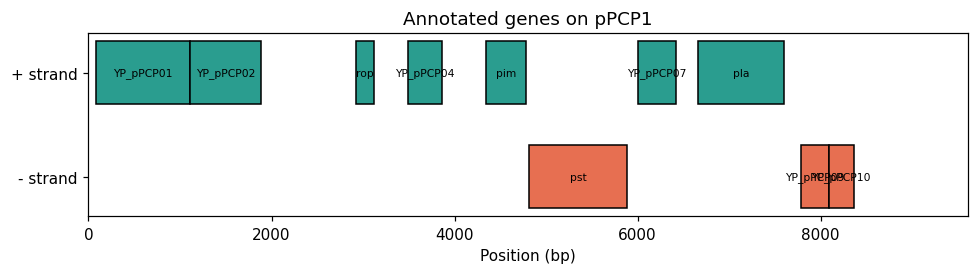

In [4]:
fig, ax = plt.subplots(figsize=(9, 2.6))
for _, r in cds.iterrows():
    y = 1 if r.strand == "+" else 0
    ax.barh(y, r.end - r.start + 1, left=r.start, height=0.6,
            color="#2a9d8f" if r.strand == "+" else "#e76f51", edgecolor="black")
    ax.text((r.start + r.end) / 2, y, r.gene or r.locus_tag, ha="center", va="center", fontsize=7)
ax.set_yticks([0, 1]); ax.set_yticklabels(["- strand", "+ strand"])
ax.set_xlim(0, len(record)); ax.set_xlabel("Position (bp)")
ax.set_title("Annotated genes on pPCP1")
plt.tight_layout(); plt.savefig("figures/gene_map.png", dpi=150); plt.show()

## 3. Simulate four strains with known mutations (truth set)
Mutations are placed on a known phylogeny: S1 and S2 share a recent ancestor (6 shared SNPs), while S3 and S4 are separate lineages. Each strain also has private SNPs.

In [5]:
rng = random.Random(123)
ref = str(record.seq).upper()
L = len(ref)
strains = ["S1", "S2", "S3", "S4"]

def pick_sites(n, used):
    sites = []
    while len(sites) < n:
        p = rng.randrange(50, L - 50)
        if p not in used and p not in sites:
            sites.append(p)
    return sites

def mutate(sites):
    return {p: rng.choice([b for b in "ACGT" if b != ref[p]]) for p in sites}

used = set()
shared = mutate(pick_sites(6, used)); used |= set(shared)
private = {}
for name, n in [("S1", 3), ("S2", 4), ("S3", 8), ("S4", 2)]:
    s = pick_sites(n, used); used |= set(s)
    private[name] = mutate(s)

truth = {
    "S1": {**shared, **private["S1"]},
    "S2": {**shared, **private["S2"]},
    "S3": private["S3"],
    "S4": private["S4"],
}
pd.DataFrame({"strain": strains, "true_SNPs": [len(truth[s]) for s in strains]})

,strain,true_SNPs
0,S1,9
1,S2,10
2,S3,8
3,S4,2


## 4. Simulate paired-end reads (FASTQ)
Reads are 2 x 100 bp at about 60x coverage with a 0.3% substitution error rate. Erroneous bases get a lower Phred quality (20 instead of 37).

In [6]:
COMP = str.maketrans("ACGT", "TGCA")
revcomp = lambda s: s.translate(COMP)[::-1]

def strain_genome(muts):
    g = list(ref)
    for p, a in muts.items():
        g[p] = a
    return "".join(g)

def add_errors(read, err=0.003):
    bases, quals = list(read), []
    for i, b in enumerate(bases):
        if rng.random() < err:
            bases[i] = rng.choice([x for x in "ACGT" if x != b]); quals.append(20)
        else:
            quals.append(37)
    return "".join(bases), "".join(chr(q + 33) for q in quals)

def simulate_pairs(genome, prefix, coverage=60, read_len=100, insert_mean=300, insert_sd=30):
    n_pairs = int(coverage * len(genome) / (2 * read_len))
    r1_lines, r2_lines = [], []
    for i in range(n_pairs):
        ins = max(int(rng.gauss(insert_mean, insert_sd)), read_len + 10)
        start = rng.randrange(0, len(genome) - ins + 1)
        frag = genome[start:start + ins]
        if rng.random() < 0.5:
            frag = revcomp(frag)
        s1, q1 = add_errors(frag[:read_len])
        s2, q2 = add_errors(revcomp(frag[-read_len:]))
        name = f"{prefix}_{i:05d}"
        r1_lines.append(f"@{name}/1\n{s1}\n+\n{q1}\n")
        r2_lines.append(f"@{name}/2\n{s2}\n+\n{q2}\n")
    return r1_lines, r2_lines

for s in strains:
    r1, r2 = simulate_pairs(strain_genome(truth[s]), s)
    for suffix, lines in (("R1", r1), ("R2", r2)):
        with gzip.open(f"data/reads/{s}_{suffix}.fastq.gz", "wt") as fh:
            fh.writelines(lines)

def fastq_stats(path):
    quals, lengths = [], []
    with gzip.open(path, "rt") as fh:
        for rec in SeqIO.parse(fh, "fastq"):
            quals.append(np.mean(rec.letter_annotations["phred_quality"]))
            lengths.append(len(rec))
    return len(lengths), np.mean(lengths), np.mean(quals)

fq = []
for s in strains:
    n, ml, mq = fastq_stats(f"data/reads/{s}_R1.fastq.gz")
    fq.append({"strain": s, "read_pairs": n, "mean_length": round(ml, 1), "mean_quality": round(mq, 1)})
pd.DataFrame(fq)

,strain,read_pairs,mean_length,mean_quality
0,S1,2882,100.0,37.0
1,S2,2882,100.0,36.9
2,S3,2882,100.0,36.9
3,S4,2882,100.0,36.9


## 5. Align reads (SAM/BAM)
`bwa mem` aligns the reads, and `samtools sort` writes a coordinate-sorted, indexed BAM file. A BAM file is the compressed binary form of a SAM file.

In [7]:
run("bwa index data/reference.fasta")
for s in strains:
    run(f"bwa mem -R '@RG\\tID:{s}\\tSM:{s}' data/reference.fasta "
        f"data/reads/{s}_R1.fastq.gz data/reads/{s}_R2.fastq.gz "
        f"| samtools sort -o data/bam/{s}.bam -")
    run(f"samtools index data/bam/{s}.bam")

out, _ = run("samtools view data/bam/S1.bam | head -n 5")
cols = ["QNAME", "FLAG", "RNAME", "POS", "MAPQ", "CIGAR", "RNEXT", "PNEXT", "TLEN", "SEQ", "QUAL"]
sam = pd.DataFrame([l.split("\t")[:11] for l in out.strip().split("\n")], columns=cols)
sam["SEQ"] = sam["SEQ"].str[:20] + "..."
sam["QUAL"] = sam["QUAL"].str[:20] + "..."
sam

,QNAME,FLAG,RNAME,POS,MAPQ,CIGAR,RNEXT,PNEXT,TLEN,SEQ,QUAL
0,S1_02022,163,NC_005816.1,2,60,100M,=,228,326,GTAACGAACGGTGCAATAGT...,FFFFFFFFFFFFFFFFFFFF...
1,S1_01086,99,NC_005816.1,5,60,100M,=,176,271,ACGAACGGTGCAATAGTGAT...,FFFFFFFFFFFFFFFFFFFF...
2,S1_00055,163,NC_005816.1,12,60,100M,=,201,289,GTGCAATAGTGATCCACACC...,FFFFFFFFFFFFFFFFFFFF...
3,S1_00300,99,NC_005816.1,13,60,100M,=,207,294,TGCAATAGTGATCCACACCC...,FFFFFFFFFFFFFFFFFFFF...
4,S1_00472,163,NC_005816.1,15,60,100M,=,219,304,CAATAGTGATCCACACCCAA...,FFFFFFFFFFFFFFFFFFFF...


The first columns of a SAM line are: read name, bit-flag (strand, pairing, mapping status), reference, position, mapping quality (MAPQ), CIGAR (alignment operations), then the mate information and the read sequence and qualities.

In [8]:
def flagstat(bam):
    out, _ = run(f"samtools flagstat {bam}")
    total = int(re.search(r"(\d+) \+ \d+ in total", out).group(1))
    mapped = float(re.search(r"mapped \((\d+\.\d+)%", out).group(1))
    paired = float(re.search(r"properly paired \((\d+\.\d+)%", out).group(1))
    return total, mapped, paired

depth = {}
rows = []
for s in strains:
    total, mapped, paired = flagstat(f"data/bam/{s}.bam")
    out, _ = run(f"samtools depth -a -d 0 data/bam/{s}.bam")
    d = pd.read_csv(io.StringIO(out), sep="\t", header=None, names=["chrom", "pos", "depth"])
    depth[s] = d["depth"].to_numpy()
    rows.append({"strain": s, "reads": total, "mapped_%": mapped, "properly_paired_%": paired,
                 "mean_depth": round(d["depth"].mean(), 1),
                 "sites_>=10x_%": round(100 * (d["depth"] >= 10).mean(), 1)})
alignment_stats = pd.DataFrame(rows)
alignment_stats

,strain,reads,mapped_%,properly_paired_%,mean_depth,sites_>=10x_%
0,S1,5764,100.0,100.0,60.0,99.6
1,S2,5764,100.0,100.0,60.0,99.4
2,S3,5764,100.0,100.0,60.0,99.5
3,S4,5764,100.0,100.0,60.0,99.2


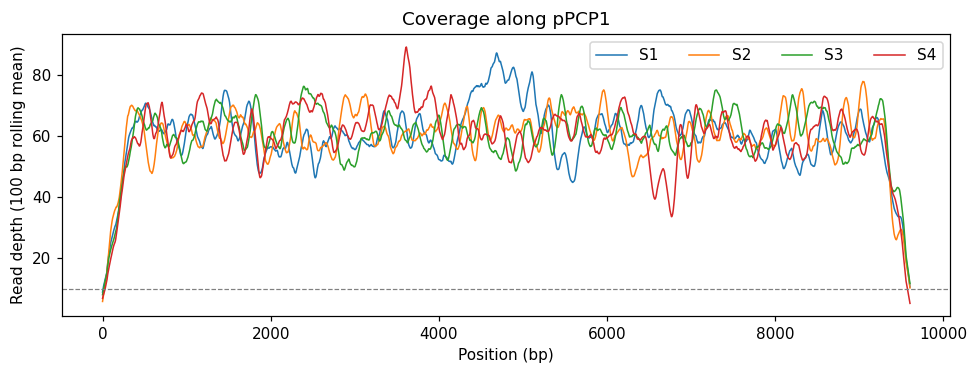

In [9]:
fig, ax = plt.subplots(figsize=(9, 3.5))
for s in strains:
    smooth = pd.Series(depth[s]).rolling(100, center=True, min_periods=1).mean()
    ax.plot(smooth, label=s, linewidth=1)
ax.axhline(10, color="grey", linestyle="--", linewidth=0.8)
ax.set_xlabel("Position (bp)"); ax.set_ylabel("Read depth (100 bp rolling mean)")
ax.set_title("Coverage along pPCP1"); ax.legend(ncol=4)
plt.tight_layout(); plt.savefig("figures/coverage.png", dpi=150); plt.show()

## 6. Call variants (VCF)
`bcftools mpileup` summarises the aligned bases at each position and `bcftools call` makes haploid genotype calls (plasmids and bacterial chromosomes are haploid). Calls are filtered to SNPs with quality of at least 30 and depth of at least 10.

In [10]:
for s in strains:
    run(f"bcftools mpileup -Ou -f data/reference.fasta data/bam/{s}.bam "
        f"| bcftools call -mv --ploidy 1 -Ov -o data/vcf/{s}.raw.vcf")
    run(f"bcftools filter -i 'QUAL>=30 && INFO/DP>=10' data/vcf/{s}.raw.vcf "
        f"| bcftools view -v snps -Ov -o data/vcf/{s}.vcf")

lines = Path("data/vcf/S1.vcf").read_text().splitlines()
print("\n".join(l for l in lines if l.startswith("##fileformat") or l.startswith("##contig")))
print("\n".join(l[:110] for l in lines if l.startswith("#CHROM")))
print("\n".join(l[:110] for l in lines if not l.startswith("#")))

##fileformat=VCFv4.2
##contig=<ID=NC_005816.1,length=9609>
#CHROM	POS	ID	REF	ALT	QUAL	FILTER	INFO	FORMAT	S1
NC_005816.1	901	.	T	C	225.417	PASS	DP=52;VDB=0.0953355;SGB=-0.693147;MQSBZ=0;MQ0F=0;AC=1;AN=1;DP4=0,0,32,20;MQ
NC_005816.1	908	.	T	A	225.417	PASS	DP=52;VDB=0.0865378;SGB=-0.693147;MQSBZ=0;MQ0F=0;AC=1;AN=1;DP4=0,0,30,22;MQ
NC_005816.1	1479	.	A	T	225.417	PASS	DP=80;VDB=0.781983;SGB=-0.693147;MQSBZ=0;MQ0F=0;AC=1;AN=1;DP4=0,0,47,33;MQ
NC_005816.1	1815	.	A	G	225.417	PASS	DP=56;VDB=0.298623;SGB=-0.693147;MQSBZ=0;MQ0F=0;AC=1;AN=1;DP4=0,0,33,23;MQ
NC_005816.1	2263	.	A	G	225.417	PASS	DP=46;VDB=0.746833;SGB=-0.693147;MQSBZ=0;MQ0F=0;AC=1;AN=1;DP4=0,0,22,24;MQ
NC_005816.1	2666	.	G	T	225.417	PASS	DP=61;VDB=0.993195;SGB=-0.693147;MQSBZ=0;MQ0F=0;AC=1;AN=1;DP4=0,0,32,29;MQ
NC_005816.1	4418	.	A	G	225.422	PASS	DP=76;VDB=0.691175;SGB=-0.693147;MQSBZ=0;MQ0F=0;AC=1;AN=1;DP4=0,0,39,37;MQ
NC_005816.1	4436	.	G	C	225.417	PASS	DP=75;VDB=0.596575;SGB=-0.693147;MQSBZ=0;MQ0F=0;AC=1;AN=1;DP4=0,0,36,39;MQ
NC_0

In [11]:
def read_vcf(path):
    rows = []
    for line in open(path):
        if line.startswith("#"):
            continue
        f = line.rstrip("\n").split("\t")
        info = dict(kv.split("=", 1) if "=" in kv else (kv, True) for kv in f[7].split(";"))
        rows.append({"pos": int(f[1]), "ref": f[3], "alt": f[4],
                     "qual": float(f[5]), "dp": int(info.get("DP", 0))})
    return pd.DataFrame(rows, columns=["pos", "ref", "alt", "qual", "dp"])

calls = {s: read_vcf(f"data/vcf/{s}.vcf") for s in strains}
called = {s: {int(r.pos) - 1: r.alt for r in calls[s].itertuples()} for s in strains}
{s: len(called[s]) for s in strains}

{'S1': 9, 'S2': 10, 'S3': 8, 'S4': 2}

## 7. Validate against the truth set
Because the mutations were simulated, every call can be checked: a **true positive** matches a simulated SNP (same position and base), a **false positive** does not, and a **false negative** is a simulated SNP that was missed.

In [12]:
rows = []
for s in strains:
    tp = sum(1 for p, a in called[s].items() if truth[s].get(p) == a)
    fp = len(called[s]) - tp
    fn = len(truth[s]) - tp
    rows.append({"strain": s, "true_SNPs": len(truth[s]), "called": len(called[s]),
                 "TP": tp, "FP": fp, "FN": fn,
                 "precision": round(tp / (tp + fp), 3) if tp + fp else float("nan"),
                 "recall": round(tp / (tp + fn), 3)})
validation = pd.DataFrame(rows)
validation.to_csv("results/validation.csv", index=False)
validation

,strain,true_SNPs,called,TP,FP,FN,precision,recall
0,S1,9,9,9,0,0,1.0,1.0
1,S2,10,10,10,0,0,1.0,1.0
2,S3,8,8,8,0,0,1.0,1.0
3,S4,2,2,2,0,0,1.0,1.0


## 8. Annotate variants with the GenBank gene model
Each SNP is mapped to the gene that contains it, and the codon change is translated (bacterial genetic code, table 11) to classify it as synonymous, missense or nonsense.

In [13]:
CDS_FEATURES = [f for f in record.features if f.type == "CDS"]
comp = {"A": "T", "C": "G", "G": "C", "T": "A"}

def annotate(pos0, alt):
    for f in CDS_FEATURES:
        positions = list(f.location)
        if pos0 not in positions:
            continue
        idx = positions.index(pos0)
        codon_idx = idx // 3
        trip = positions[codon_idx * 3: codon_idx * 3 + 3]
        strand = f.location.strand
        fix = (lambda b: comp[b]) if strand == -1 else (lambda b: b)
        ref_codon = "".join(fix(ref[p]) for p in trip)
        alt_bases = [fix(alt) if p == pos0 else fix(ref[p]) for p in trip]
        alt_codon = "".join(alt_bases)
        from Bio.Seq import Seq
        ref_aa = str(Seq(ref_codon).translate(table=11))
        alt_aa = str(Seq(alt_codon).translate(table=11))
        if ref_aa == alt_aa:
            effect = "synonymous"
        elif alt_aa == "*":
            effect = "nonsense"
        else:
            effect = "missense"
        q = f.qualifiers
        return {"gene": q.get("gene", [q.get("locus_tag", [""])[0]])[0],
                "product": q.get("product", [""])[0],
                "codon": f"{ref_codon}>{alt_codon}", "aa_change": f"{ref_aa}{codon_idx + 1}{alt_aa}",
                "effect": effect}
    return {"gene": "intergenic", "product": "", "codon": "", "aa_change": "", "effect": "intergenic"}

rows = []
for s in strains:
    for r in calls[s].itertuples():
        a = annotate(int(r.pos) - 1, r.alt)
        rows.append({"strain": s, "pos": int(r.pos), "ref": r.ref, "alt": r.alt,
                     "qual": r.qual, "depth": r.dp, **a})
variants = pd.DataFrame(rows)
variants.to_csv("results/annotated_variants.csv", index=False)
variants

,strain,pos,ref,alt,qual,depth,gene,product,codon,aa_change,effect
0,S1,901,T,C,225.417,52,YP_pPCP01,putative transposase,CTG>CCG,L272P,missense
1,S1,908,T,A,225.417,52,YP_pPCP01,putative transposase,GAT>GAA,D274E,missense
2,S1,1479,A,T,225.417,80,YP_pPCP02,transposase/IS protein,TAT>TTT,Y125F,missense
3,S1,1815,A,G,225.417,56,YP_pPCP02,transposase/IS protein,CAA>CGA,Q237R,missense
4,S1,2263,A,G,225.417,46,intergenic,,,,intergenic
5,S1,2666,G,T,225.417,61,intergenic,,,,intergenic
6,S1,4418,A,G,225.422,76,pim,pesticin immunity protein,AAC>GAC,N26D,missense
7,S1,4436,G,C,225.417,75,pim,pesticin immunity protein,GAC>CAC,D32H,missense
8,S1,6723,A,T,225.417,66,pla,outer membrane protease,GCA>GCT,A20A,synonymous
9,S2,78,G,C,168.416,26,intergenic,,,,intergenic


effect
missense      17
intergenic     7
synonymous     5


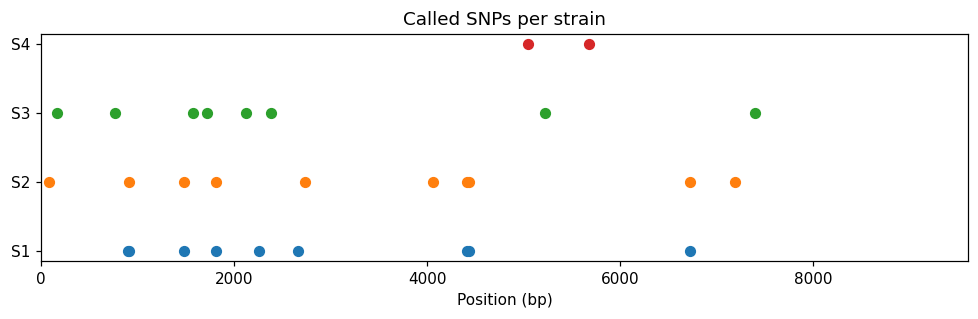

In [14]:
print(variants["effect"].value_counts().to_string())

fig, ax = plt.subplots(figsize=(9, 3))
for i, s in enumerate(strains):
    ax.scatter(calls[s]["pos"], [i] * len(calls[s]), s=40)
ax.set_yticks(range(len(strains))); ax.set_yticklabels(strains)
ax.set_xlim(0, L); ax.set_xlabel("Position (bp)"); ax.set_title("Called SNPs per strain")
plt.tight_layout(); plt.savefig("figures/variant_positions.png", dpi=150); plt.show()

## 9. Build a strain tree (Newick)
A SNP matrix is built from the called sites (a strain carries the alternative base where it was called, otherwise the reference base). Pairwise SNP distances feed a neighbour-joining tree, which is rooted on the reference and written in Newick format. The tree is checked against the distances implied by the true mutations.

In [15]:
taxa = ["Reference"] + strains
sites = sorted(set().union(*[set(called[s]) for s in strains]))

def genotype(t):
    if t == "Reference":
        return {p: ref[p] for p in sites}
    return {p: called[t].get(p, ref[p]) for p in sites}

geno = {t: genotype(t) for t in taxa}
snp_dist = lambda a, b: sum(geno[a][p] != geno[b][p] for p in sites)

matrix = [[snp_dist(taxa[i], taxa[j]) for j in range(i + 1)] for i in range(len(taxa))]
dm = DistanceMatrix(taxa, matrix)

tree = DistanceTreeConstructor().nj(dm)
tree.root_with_outgroup("Reference")
Phylo.write(tree, "results/strains.nwk", "newick")
print(Path("results/strains.nwk").read_text())

tr = {"Reference": set()}
tr.update({s: {(p, a) for p, a in truth[s].items()} for s in strains})
true_dist = pd.DataFrame([[len(tr[a] ^ tr[b]) for b in taxa] for a in taxa], index=taxa, columns=taxa)
est_dist = pd.DataFrame([[snp_dist(a, b) for b in taxa] for a in taxa], index=taxa, columns=taxa)
print("Estimated SNP distances equal the true distances:", bool(true_dist.equals(est_dist)))
est_dist

(((S3:8,S4:2)Inner3:0,(S2:4,S1:3)Inner1:6)Inner2:0,Reference:0):0;

Estimated SNP distances equal the true distances: True


,Reference,S1,S2,S3,S4
Reference,0,9,10,8,2
S1,9,0,7,17,11
S2,10,7,0,18,12
S3,8,17,18,0,10
S4,2,11,12,10,0


  ____________________________________________________ S3
 |
 |____________ S4
 |
 |                                        __________________________ S2
_|_______________________________________|
 |                                       |___________________ S1
 |
 | Reference



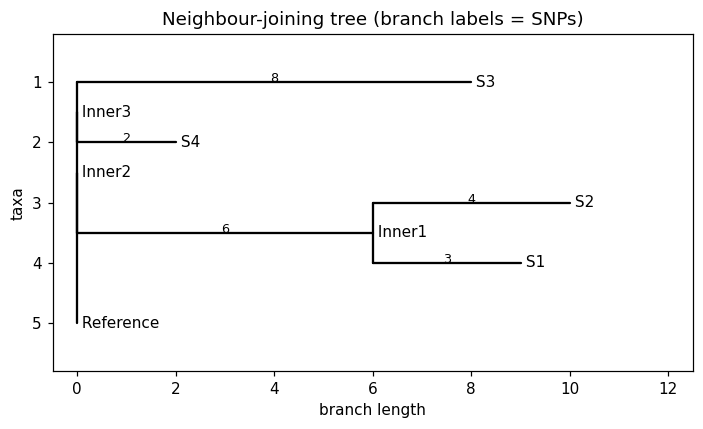

In [16]:
tree_back = Phylo.read("results/strains.nwk", "newick")
Phylo.draw_ascii(tree_back)

fig, ax = plt.subplots(figsize=(6.5, 4))
Phylo.draw(tree_back, axes=ax, do_show=False,
           branch_labels=lambda c: f"{c.branch_length:.0f}" if c.branch_length else None)
ax.set_title("Neighbour-joining tree (branch labels = SNPs)")
plt.tight_layout(); plt.savefig("figures/strain_tree.png", dpi=150); plt.show()

**Reading the tree:** branch labels are numbers of SNPs. Branches of length 0 mean the order of splitting is unresolved (a polytomy). Here S3, S4 and the clade formed by S1 and S2 all branch directly from the reference node, with S1 and S2 sharing a 6-SNP branch. This matches the simulation, where S3, S4 and the ancestor of S1 and S2 were each derived independently from the reference.

## 10. Files produced

In [17]:
files = sorted(p for p in Path(".").rglob("*") if p.is_file()
               and p.parts[0] in ("data", "results", "figures")
               and not p.name.endswith((".amb", ".ann", ".bwt", ".pac", ".sa")))
pd.DataFrame({"file": [str(p) for p in files], "size_KB": [round(p.stat().st_size / 1024, 1) for p in files]})

,file,size_KB
0,data/NC_005816.gb,31.1
1,data/bam/S1.bam,132.1
2,data/bam/S1.bam.bai,0.1
3,data/bam/S2.bam,133.7
4,data/bam/S2.bam.bai,0.1
5,data/bam/S3.bam,132.9
6,data/bam/S3.bam.bai,0.1
7,data/bam/S4.bam,131.0
8,data/bam/S4.bam.bai,0.1
9,data/reads/S1_R1.fastq.gz,69.6


## 11. Limitations
- The strains and reads are simulated, so accuracy is measured on an idealised case: uniform coverage, substitution errors only, no indels, no repeats, no contamination.
- A 9.6 kb plasmid is far smaller than a bacterial chromosome; runtime and coverage evenness would differ on a real genome.
- The tree uses SNPs only and assumes no recombination, which is often not true in bacteria.
- Filtering thresholds (QUAL 30, depth 10) were set by convention, not tuned.
- Read trimming and quality control, which real data need, were not included.

## 12. Reproducibility

In [18]:
print("Python", sys.version.split()[0], "| Biopython", Bio.__version__, "| pandas", pd.__version__)
print(run("samtools --version | head -n 1")[0].strip())
print(run("bcftools --version | head -n 1")[0].strip())
print(run("bwa 2>&1 | grep -i '^Version'")[0].strip())

Python 3.13.18 | Biopython 1.88 | pandas 2.2.3
samtools 1.19.2
bcftools 1.19
Version: 0.7.17-r1188


In [19]:
# Bundle the outputs (on Google Colab this also downloads the zip)
import zipfile
skip = (".amb", ".ann", ".bwt", ".pac", ".sa")
with zipfile.ZipFile("pipeline_outputs.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for folder in ("data", "results", "figures"):
        for p in Path(folder).rglob("*"):
            if p.is_file() and not p.name.endswith(skip):
                z.write(p)
try:
    from google.colab import files as colab_files
    colab_files.download("pipeline_outputs.zip")
except ImportError:
    pass

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>